# Backtest: does a 2-regime model forecast better than 1 regime? (train 2000–2019, test 2020–2026)

**Hypothesis.** Splitting the market into calm/crisis regimes (HMM) gives better forecasts of the S&P 500 than one equation fitted on all data.

**Comparison, pair by pair (same solver inside each pair):**

| pair | model A | model B |
|---|---|---|
| FD  | 2 regimes, FD  | 1 regime, FD  |
| WAN | 2 regimes, WAN | 1 regime, WAN |

**Setup**
- Data: daily S&P 500 closes `data/sp500.csv`. Train = before 2020-01-01, test = 2020-01-02 … the last date.
- Target: the log-return over the next *h* = 1, 5, 21 trading days.
- Parameters are frozen at the end of 2019. During the test only the regime probabilities are updated, by filtering each new daily return (no look-ahead; the backtester checks this automatically).
- PDE: $F_i(\tau,z)=P(X_\tau\le z\mid \text{regime } i)$ solves $\partial_\tau F_i=\tfrac12\sigma_i^2F_i''-m_iF_i'+\sum_j q_{ij}F_j$, $F_i(0,z)=\mathbf 1\{z\ge0\}$, the same coupled system as regime-switching option pricing. For 1 regime it is a single equation. It is solved once; the daily forecast is $\sum_i P(\text{regime } i\text{ today})\,F_i(h,z)$.

**Errors (main scores, in % of log-return)**
- *Point forecast*: forecast mean vs realised h-day return, RMSE (L2); forecast median, MAE (L1).
- *Volatility forecast*: forecast standard deviation vs realised volatility $\sqrt{\sum_{k=1}^h r_{t+k}^2}$, RMSE (L2).
- Secondary: squared L2 distance between forecast CDF and the realised step function (this is exactly the CRPS), VaR breach rates.
- Pairs are tested with the Diebold–Mariano test on the squared errors.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt

from data import load_returns, load_prices, split
from backtest import run_backtest, compare_pairs
from models import RegimeSwitchingPDE
import hmm

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
TEST_START = "2020-01-01"
returns, prices = load_returns(), load_prices()
train, test = split(returns, TEST_START)
print(f"train: {train.index[0].date()} .. {train.index[-1].date()}  ({len(train)} days)")
print(f"test : {test.index[0].date()} .. {test.index[-1].date()}  ({len(test)} days)")

train: 2000-01-04 .. 2019-12-31  (5030 days)
test : 2020-01-02 .. 2026-11-04  (1720 days)


## 1. Regimes from the HMM (fitted on 2000–2019 only)

                   log-drift (annual)  ...  mean duration (years)
2 regimes: calm                 0.178  ...                  0.350
2 regimes: crisis              -0.261  ...                  0.157
1 regime                        0.040  ...                    inf

[3 rows x 3 columns]

Generator Q (per year):
 [[-2.86  2.86]
 [ 6.38 -6.38]]


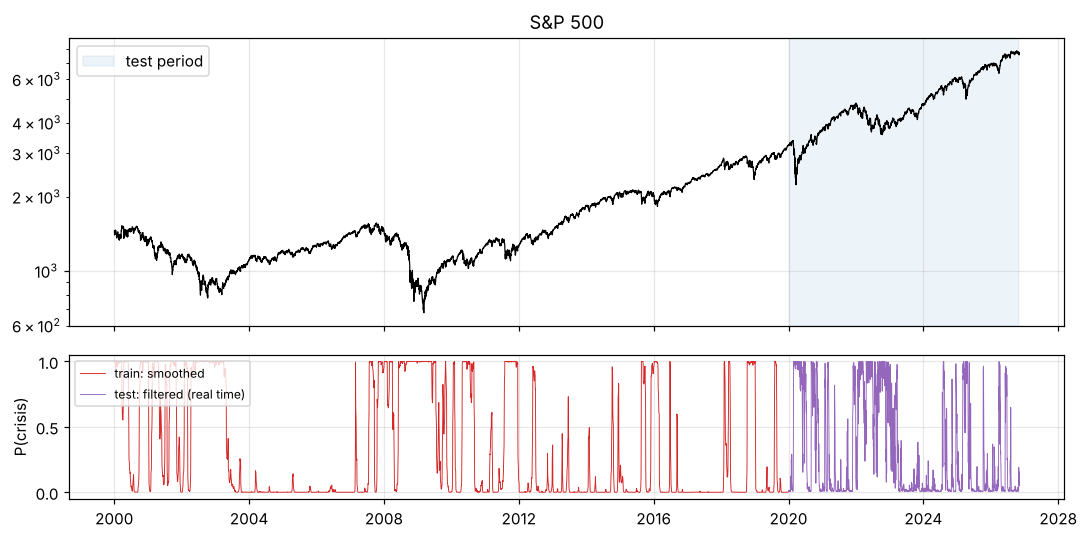

In [2]:
fit = hmm.fit_gaussian_hmm(train.values, m=2)
drift, sigma, Q = hmm.to_continuous(fit)
fit1 = hmm.fit_gaussian_hmm(train.values, m=1)
d1, s1, _ = hmm.to_continuous(fit1)
print(pd.DataFrame({"log-drift (annual)": np.r_[drift, d1], "volatility (annual)": np.r_[sigma, s1],
                    "mean duration (years)": np.r_[-1 / np.diag(Q), np.inf]},
                   index=["2 regimes: calm", "2 regimes: crisis", "1 regime"]).round(3))
print("\nGenerator Q (per year):\n", Q.round(2))

p_train = fit["gamma"][:, 1]
p0 = hmm.filter_probs(train.values, fit)[-1]
p_test = hmm.filter_probs(test.values, fit, p0=p0)[:, 1]
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(prices.index, prices.values, lw=0.8, color="k"); ax[0].set_yscale("log")
ax[0].axvspan(pd.Timestamp(TEST_START), prices.index[-1], color="tab:blue", alpha=0.08, label="test period")
ax[0].set_title("S&P 500"); ax[0].legend(loc="upper left")
ax[1].plot(train.index, p_train, lw=0.6, color="tab:red", label="train: smoothed")
ax[1].plot(test.index, p_test, lw=0.6, color="tab:purple", label="test: filtered (real time)")
ax[1].set_ylabel("P(crisis)"); ax[1].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig("../results/figs/regimes.png"); plt.show()

## 2. Run the backtest

Four models: {1, 2} regimes × {FD, WAN}. Each WAN trains once (about 3 minutes on a CPU).

In [3]:
models = [RegimeSwitchingPDE(m, s) for s in ("fd", "wan") for m in (1, 2)]
PAIRS = [("2 regimes, FD", "1 regime, FD"), ("2 regimes, WAN", "1 regime, WAN")]
table, details = run_backtest(models, returns, test_start=TEST_START)
dm = compare_pairs(details, PAIRS)
table.to_csv("../results/metrics.csv", index=False); dm.to_csv("../results/dm_tests.csv", index=False)

1 regime, FD     done in    0.6s   look-ahead check: max change 0.0e+00
2 regimes, FD    done in    2.6s   look-ahead check: max change 0.0e+00
1 regime, WAN    done in  163.6s   look-ahead check: max change 0.0e+00
2 regimes, WAN   done in  210.2s   look-ahead check: max change 0.0e+00


## 3. Forecast errors

In [4]:
order = [m.name for m in models]
main = ["RMSE_mean", "MAE_median", "RMSE_vol"]
for h, g in table.groupby("horizon"):
    print(f"\n=== horizon {h} trading days: errors in % (lower = better) ===")
    print(g.set_index("model").loc[order, main + ["CDF_L2sq"]].round(3).to_string())

print("\n\nPair tests: ratio = mean squared error of A / of B  (< 1: 2 regimes better);"
      " DM t < 0: 2 regimes better")
for (a, b), g in dm.groupby(["A", "B"], sort=False):
    print(f"\n--- {a}  vs  {b} ---")
    print(g.pivot(index="loss", columns="horizon", values="ratio_A_over_B").round(3).to_string())
    print("p-values:")
    print(g.pivot(index="loss", columns="horizon", values="p_value").round(3).to_string())


=== horizon 1 trading days: errors in % (lower = better) ===
                RMSE_mean  MAE_median  RMSE_vol  CDF_L2sq
model                                                    
1 regime, FD        1.271        0.83     1.026     0.632
2 regimes, FD       1.273        0.83     0.941     0.610
1 regime, WAN       1.271        0.83     1.026     0.632
2 regimes, WAN      1.272        0.83     0.946     0.610

=== horizon 5 trading days: errors in % (lower = better) ===
                RMSE_mean  MAE_median  RMSE_vol  CDF_L2sq
model                                                    
1 regime, FD        2.579       1.806     1.812     1.349
2 regimes, FD       2.607       1.817     1.555     1.312
1 regime, WAN       2.579       1.806     1.812     1.349
2 regimes, WAN      2.600       1.814     1.572     1.310

=== horizon 21 trading days: errors in % (lower = better) ===
                RMSE_mean  MAE_median  RMSE_vol  CDF_L2sq
model                                                    
1

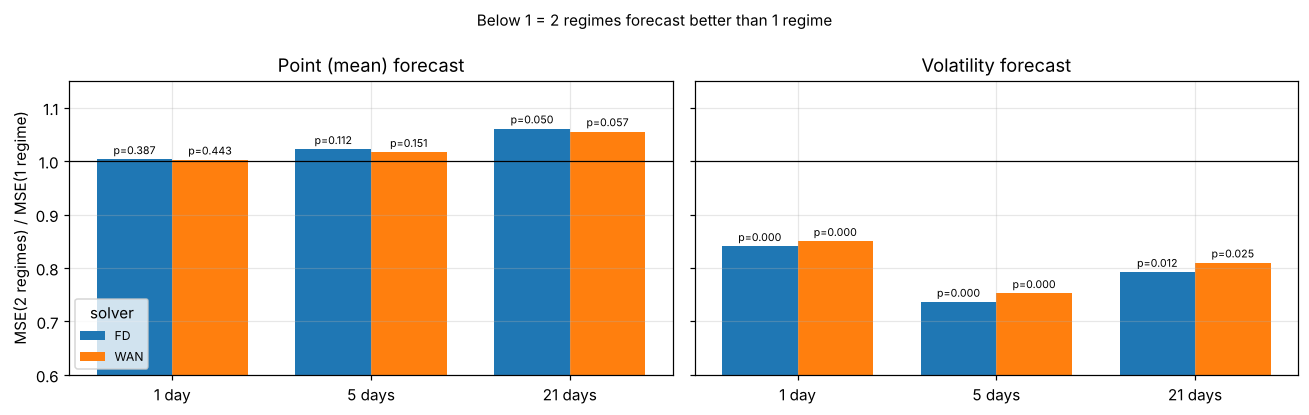

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
H = [1, 5, 21]; w = 0.38
for k, loss in enumerate(["point (mean), squared error", "volatility, squared error"]):
    for j, (a, b) in enumerate(PAIRS):
        g = dm[(dm.A == a) & (dm.loss == loss)].set_index("horizon").loc[H]
        x = np.arange(len(H)) + (j - 0.5) * w
        bars = ax[k].bar(x, g.ratio_A_over_B, w, color=f"C{j}", label=a.split(", ")[1])
        for xi, (rat, p) in zip(x, zip(g.ratio_A_over_B, g.p_value)):
            ax[k].text(xi, rat + 0.01, f"p={p:.3f}", ha="center", fontsize=7)
    ax[k].axhline(1, color="k", lw=0.8)
    ax[k].set_xticks(range(len(H)), [f"{h} day" + ("s" if h > 1 else "") for h in H])
    ax[k].set_title(loss.split(",")[0].capitalize() + " forecast")
    ax[k].set_ylim(0.6, 1.15)
ax[0].set_ylabel("MSE(2 regimes) / MSE(1 regime)"); ax[0].legend(title="solver", fontsize=8, loc="lower left")
fig.suptitle("Below 1 = 2 regimes forecast better than 1 regime", fontsize=10)
plt.tight_layout(); plt.savefig("../results/figs/error_ratios.png"); plt.show()

## 4. What the forecasts look like (FD pair, 5-day horizon)

Left: forecast volatility vs realised volatility. Right: forecast mean (point forecast) vs realised return.

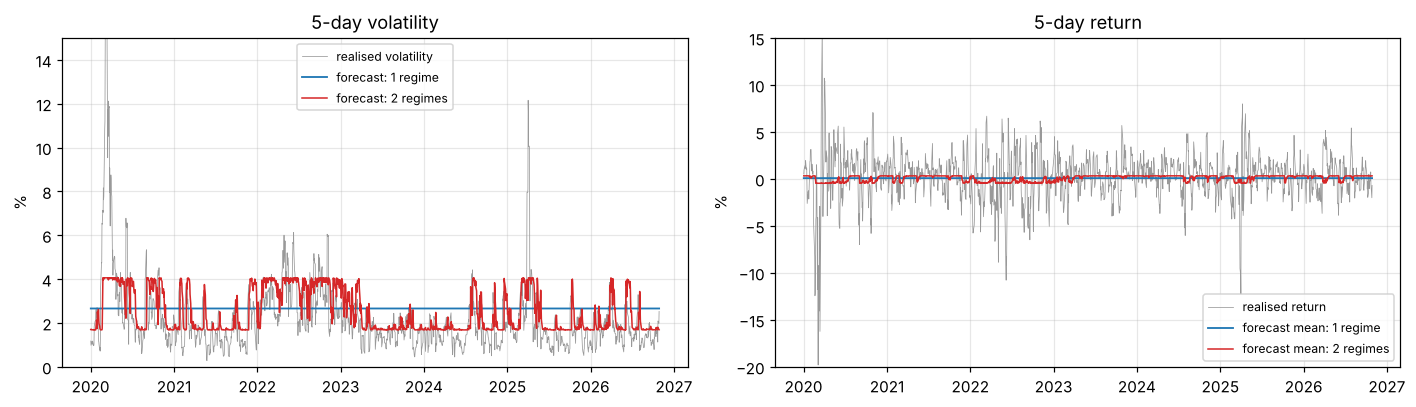

In [6]:
h = 5
a, b = details["2 regimes, FD"][h], details["1 regime, FD"][h]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(a["dates"], 100 * a["rv"], lw=0.5, color="0.6", label="realised volatility")
ax[0].plot(b["dates"], 100 * b["std"], lw=1.2, color="C0", label="forecast: 1 regime")
ax[0].plot(a["dates"], 100 * a["std"], lw=1.0, color="C3", label="forecast: 2 regimes")
ax[0].set(ylim=(0, 15), ylabel="%", title=f"{h}-day volatility"); ax[0].legend(fontsize=8)
ax[1].plot(a["dates"], 100 * a["y"], lw=0.5, color="0.6", label="realised return")
ax[1].plot(b["dates"], 100 * b["mean"], lw=1.2, color="C0", label="forecast mean: 1 regime")
ax[1].plot(a["dates"], 100 * a["mean"], lw=1.0, color="C3", label="forecast mean: 2 regimes")
ax[1].set(ylim=(-20, 15), ylabel="%", title=f"{h}-day return"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("../results/figs/forecasts.png"); plt.show()

## 5. WAN vs FD: same PDE, how close are the solutions?

In [7]:
from pde.fd import solve_cdf_fd
zz = np.linspace(-0.4, 0.4, 801)
rows = []
for m_reg in (1, 2):
    fdm = next(m for m in models if m.m == m_reg and m.solver == "fd")
    wm = next(m for m in models if m.m == m_reg and m.solver == "wan")
    z_fd, sol_fd = solve_cdf_fd(fdm.params, [1, 5, 21])
    sol_w = wm.wan.solve([1, 5, 21], zz)
    for h in (1, 5, 21):
        for i in range(m_reg):
            diff = np.abs(sol_w[h][i] - np.interp(zz, z_fd, sol_fd[h][i])).max()
            rows.append(dict(model=f"{m_reg} regime(s)", start=["calm", "crisis"][i] if m_reg == 2 else "-",
                             horizon=h, max_abs_CDF_diff=diff))
    print(f"{wm.name}: training {wm.wan.train_time:.0f}s")
print(pd.DataFrame(rows).pivot_table(index=["model", "start"], columns="horizon",
                                     values="max_abs_CDF_diff").round(4).to_string())

1 regime, WAN: training 163s
2 regimes, WAN: training 208s
horizon                 1       5       21
model       start                         
1 regime(s) -       0.0001  0.0002  0.0001
2 regime(s) calm    0.0032  0.0090  0.0076
            crisis  0.0034  0.0074  0.0071


## 6. Findings

Ratios are the mean squared error of the 2-regime model divided by that of the 1-regime model; below 1 means 2 regimes are better.

| | 1 day | 5 days | 21 days |
|---|---|---|---|
| **Volatility forecast**, FD pair | 0.84 (p < 0.001) | 0.74 (p < 0.001) | 0.79 (p = 0.012) |
| **Volatility forecast**, WAN pair | 0.85 (p < 0.001) | 0.75 (p < 0.001) | 0.81 (p = 0.025) |
| **Point forecast (mean)**, FD pair | 1.00 (p = 0.39) | 1.02 (p = 0.11) | 1.06 (p = 0.050) |
| **Point forecast (mean)**, WAN pair | 1.00 (p = 0.44) | 1.02 (p = 0.15) | 1.06 (p = 0.057) |

**1. Regimes forecast risk, not direction.** Two regimes cut the squared error of the volatility forecast by 15–26% at every horizon, significant for both solvers. The point forecast of the return does not improve; at 21 days it is about 6% worse (borderline significant). The crisis regime's negative drift (−26% a year) pulls the forecast down after sell-offs, and in 2020–2026 the market mostly rebounded. Returns themselves stay close to unpredictable, while volatility is predictable. That is exactly what the regime filter captures (see the 5-day plot: the forecast moves between about 1.8% and 4% with the market).

**2. Both solvers lead to the same conclusion.** The WAN pair reproduces the FD pair to within about 0.02 in every ratio. The 2-regime WAN CDF differs from FD by at most 0.009.

**3. Note on the 1-regime WAN.** For one regime the WAN's base function (the exact normal CDF) already solves the equation, so the network has nothing left to learn (difference from FD ≈ 0.0001). The real test of the WAN is the 2-regime system.

**4. A WAN lesson worth reporting.** The first version of the 2-regime WAN gave a much worse 21-day volatility forecast (RMSE 3.61% vs 2.94% for FD), which flipped the WAN pair's conclusion. The cause was about 1% of spurious probability far in the left tail (z ≈ −0.45). The CDF error there was small, so the weak loss hardly saw it, but it inflated the standard deviation from 4.0% to 6.3%. Two fixes solved it: a Gaussian envelope that keeps the network's correction where the distribution lives, and monotone rearrangement of the CDF (sorting it along z). So a small CDF error is not enough; *moments* of the WAN solution have to be checked too.

**Caveats.** There is one train/test split and one market (the S&P 500). Parameters are frozen at 2019. The switching rates are high (a calm spell lasts about 4 months on average). Within each regime returns are Gaussian, so tails are too thin: the 1-day 1% VaR is breached 1.7–2.2% of the time instead of 1% (metrics.csv).

## 7. How to test another algorithm

Any algorithm plugs in through one interface (`src/models/base.py`): `fit(train_returns)` and `predict_cdf(returns, n_test, horizons, z_grids)`, returning the forecast CDF for every test day. All errors above are computed from that CDF, so a new model gets every score automatically. Row *k* may use data up to test day *k* only (the backtester checks it).

```python
from models.base import ForecastModel

class MyModel(ForecastModel):
    name = "my model"
    def fit(self, train_returns):
        ...                                   # estimate on 2000-2019
    def predict_cdf(self, returns, n_test, horizons, z_grids):
        ...                                   # return {h: array (n_test, len(z_grids[h]))}

table, details = run_backtest([RegimeSwitchingPDE(1, "fd"), MyModel()], returns)
dm = compare_pairs(details, [("my model", "1 regime, FD")])
```

Ideas: `RegimeSwitchingPDE(3, "fd")`, Student-t returns inside each regime, rolling re-estimation, the PyTorch WAN.